In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import ADASYN

# **Load Dataset**

In [ ]:
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
print("5 Data Pertama")
display(df.head())

5 Data Pertama


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
print("\nInformasi Dataset")
print(df.info())


Informasi Dataset
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB
None


In [ ]:
print("\nUkuran Dataset")
print(df.shape)


Ukuran Dataset
(5110, 12)


# **Exploratory Data Analysis Sebelum Preprocessing**

## Cek Missing Value

In [ ]:
print("\nJumlah Missing Value")
print(df.isnull().sum())


Jumlah Missing Value
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


## Cek Duplicate Data

In [ ]:
print("\nJumlah Duplicate Data")
print(df.duplicated().sum())


Jumlah Duplicate Data
0


## Cek Distribusi Target

In [ ]:
print("\nJumlah Kelas Target")
print(df['stroke'].value_counts())

print("\nPersentase Kelas")
print(df['stroke'].value_counts(normalize=True)*100)


Jumlah Kelas Target
stroke
0    4861
1     249
Name: count, dtype: int64

Persentase Kelas
stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64


## Visualisasi Distribusi Target

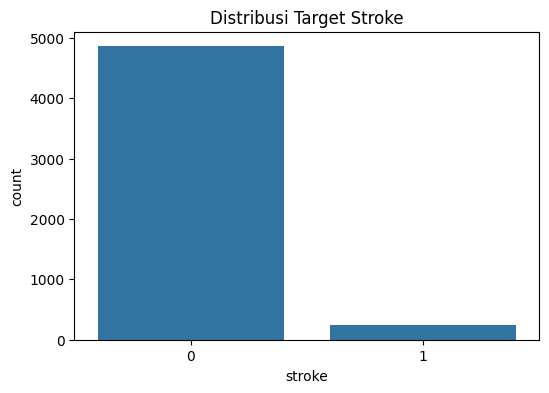

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x='stroke', data=df)
plt.title('Distribusi Target Stroke')
plt.show()

## Visualisasi Fitur Numerik

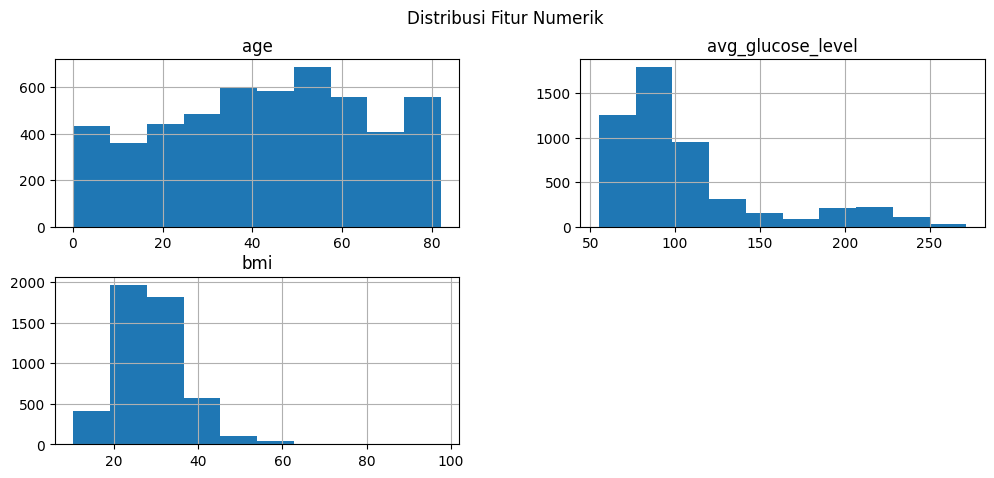

In [ ]:
numerical_cols = ['age', 'avg_glucose_level', 'bmi']
df[numerical_cols].hist(figsize=(12,5))
plt.suptitle('Distribusi Fitur Numerik')
plt.show()

## Cek Outlier dengan boxplot

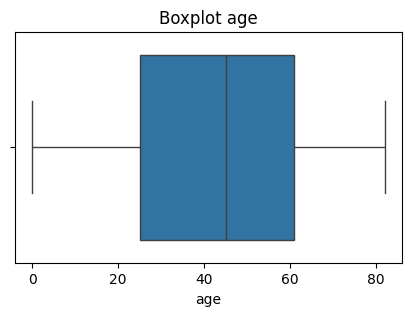

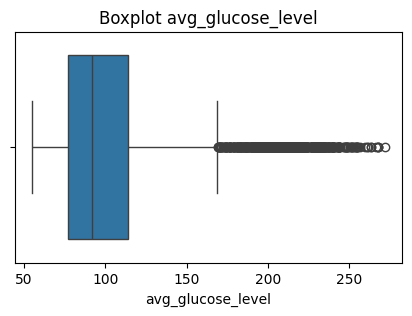

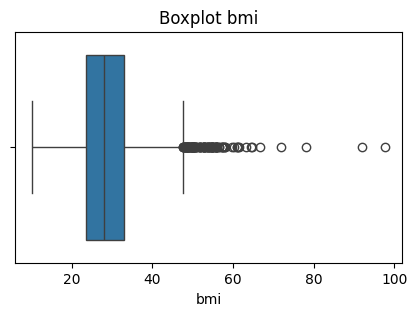

In [ ]:
for col in numerical_cols:
    plt.figure(figsize=(5,3))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot {col}')
    plt.show()

# **Preprocessing**

## Handle Missing Value

Mengisi missing value BMI menggunakan median

In [ ]:
df['bmi'].fillna(df['bmi'].median(), inplace=True)
print("\nMissing Value Setelah Handling")
print(df.isnull().sum())


Missing Value Setelah Handling
id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


/tmp/ipykernel_2141/1975010242.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['bmi'].fillna(df['bmi'].median(), inplace=True)


## Drop Kolom ID

Di drop karena hanya sebagai identitas pasien

In [ ]:
df.drop('id', axis=1, inplace=True)
print("\nKolom Setelah Drop ID")
print(df.columns)


Kolom Setelah Drop ID
Index(['gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')


# **Feature Engineering**

## One Hot Encoding

In [ ]:
X = df.drop('stroke', axis=1)
y = df['stroke']

print("\nShape Fitur")
print(X.shape)

print("\nShape Target")
print(y.shape)


Shape Fitur
(5110, 10)

Shape Target
(5110,)


# **EDA setelah prepro dan FE**

## Visualisasi stroke berdasarkan gender

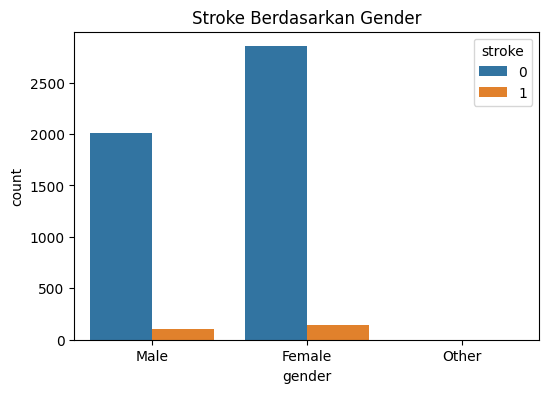

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(x='gender', hue='stroke', data=df)

plt.title('Stroke Berdasarkan Gender')

plt.show()

## Visualisasi Stroke berdasarkan smoking status

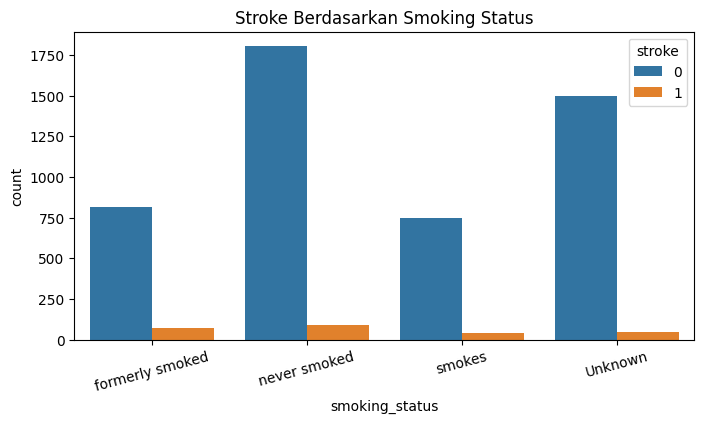

In [ ]:
plt.figure(figsize=(8,4))

sns.countplot(x='smoking_status', hue='stroke', data=df)

plt.title('Stroke Berdasarkan Smoking Status')

plt.xticks(rotation=15)

plt.show()

## Visualisasi Stroke Berdasarkan Age Category

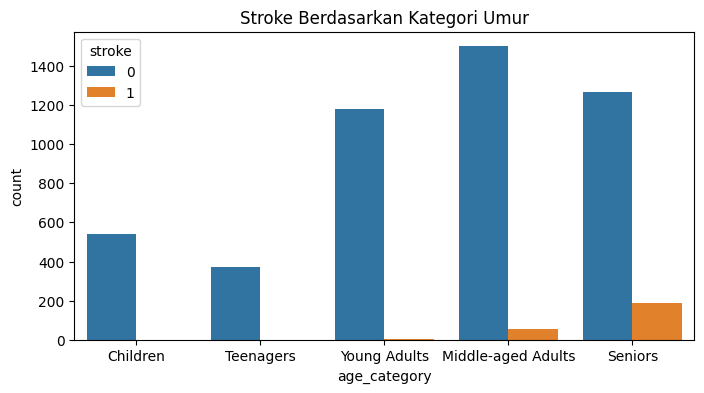

In [ ]:
bins = [0, 12, 19, 39, 59, np.inf]
labels = ['Children', 'Teenagers', 'Young Adults', 'Middle-aged Adults', 'Seniors']
df['age_category'] = pd.cut(df['age'], bins=bins, labels=labels, right=False)

plt.figure(figsize=(8,4))

sns.countplot(
    x='age_category',
    hue='stroke',
    data=df
)

plt.title('Stroke Berdasarkan Kategori Umur')

plt.show()

# **Split data training dan testing**

Membagi data 80% training dan 20% testing

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,

    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah Data Training :", X_train.shape)
print("Jumlah Data Testing  :", X_test.shape)

Jumlah Data Training : (4088, 10)
Jumlah Data Testing  : (1022, 10)


In [ ]:
# Kolom Numerik dan Kategorikal

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerik:", numeric_features)

print("\nKategorikal:", categorical_features)

Numerik: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']

Kategorikal: ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']


In [ ]:
# Pipeline Numerik

numeric_transformer = Pipeline(steps=[

    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler())

])


In [ ]:
# Pipeline Kategorikal

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])


In [ ]:
# Gabungkan Preprocessing

preprocessor = ColumnTransformer(

    transformers=[

        ("num", numeric_transformer, numeric_features),

        ("cat", categorical_transformer, categorical_features)

    ]

)

print("\n=== Preprocessing Pipeline ===")
print("Kolom numerik    :", numeric_features)
print("Kolom kategorikal:", categorical_features)


=== Preprocessing Pipeline ===
Kolom numerik    : ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']
Kolom kategorikal: ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']


# **Balancing Dataset**

## Cek Distribusi Target Sebelum Adasyn

In [ ]:
print("\nJumlah Kelas Training Sebelum ADASYN")
print(y_train.value_counts())

print("\nPersentase Kelas Training")
print(y_train.value_counts(normalize=True) * 100)

ratio = y_train.value_counts().max() / y_train.value_counts().min()
print(f"\nRasio kelas (mayoritas/minoritas): {ratio:.2f}")


Jumlah Kelas Training Sebelum ADASYN
stroke
0    3889
1     199
Name: count, dtype: int64

Persentase Kelas Training
stroke
0    95.132094
1     4.867906
Name: proportion, dtype: float64

Rasio kelas (mayoritas/minoritas): 19.54


# Perbandinga Teknik ADASYN dan SMOTE

# **1. ADASYN**

# Optimasi Hyperparameter

In [ ]:
!pip install scikit-optimize

from sklearn.model_selection import StratifiedKFold
from skopt import BayesSearchCV
from skopt.space import Integer, Real, Categorical
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import ADASYN
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC

##### Stratified K-Fold

In [ ]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
def build_pipeline(model):
    return ImbPipeline(steps=[
        ("preprocess", preprocessor),
        ("adasyn", ADASYN(random_state=42)),
        ("model", model)
    ])

### Random Forest

##### Parameter Random Forest

In [ ]:
rf_params = {
    'model__n_estimators': Integer(50, 300),
    'model__max_depth': Integer(3, 20),
    'model__min_samples_split': Integer(2, 10),
    'model__min_samples_leaf': Integer(1, 10)
}

##### Model Random Forest

In [ ]:
rf_model = RandomForestClassifier(
    random_state=42,
    class_weight='balanced'
)

##### Bayesian Optimization

In [ ]:
rf_opt = BayesSearchCV(
    estimator=build_pipeline(rf_model),

    search_spaces=rf_params,

    n_iter=20,

    cv=skf,

    scoring='f1',

    n_jobs=-1,

    random_state=42
)

rf_opt.fit(X_train, y_train)

print("\nBest Parameter Random Forest")
print(rf_opt.best_params_)


Best Parameter Random Forest
OrderedDict({'model__max_depth': 7, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 92})


### XGBOOST

##### Parameter XGBOOST

In [ ]:
xgb_params = {
    'model__n_estimators': Integer(50, 300),
    'model__max_depth': Integer(3, 15),
    'model__learning_rate': Real(0.01, 0.3, prior='log-uniform'),
    'model__subsample': Real(0.5, 1.0, prior='uniform'),
    'model__colsample_bytree': Real(0.5, 1.0, prior='uniform')
}

##### Model XGBOOST

In [ ]:
scale_pos_weight = (
    y_train.value_counts()[0] /
    y_train.value_counts()[1]
)

In [ ]:
xgb_model = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    scale_pos_weight=scale_pos_weight
)

##### Bayesian Optimization

In [ ]:
xgb_opt = BayesSearchCV(
    estimator=build_pipeline(xgb_model),

    search_spaces=xgb_params,

    n_iter=20,

    cv=skf,

    scoring='f1',

    n_jobs=-1,

    random_state=42
)

xgb_opt.fit(X_train, y_train)

print("\nBest Parameter XGBoost")
print(xgb_opt.best_params_)


Best Parameter XGBoost
OrderedDict({'model__colsample_bytree': 0.5, 'model__learning_rate': 0.23853450113551763, 'model__max_depth': 3, 'model__n_estimators': 239, 'model__subsample': 0.5})


### Support Vector Machine (SVM)

##### Parameter SVM

In [ ]:
svm_params = {
    'model__C': Real(0.1, 100.0, prior='log-uniform'),
    'model__gamma': Real(0.0001, 1.0, prior='log-uniform'),
    'model__kernel': Categorical(['rbf'])
}

##### Model SVM

In [ ]:
svm_model = SVC(
    probability=True,
    random_state=42,
    class_weight='balanced'
)

##### Bayesian Optimization

In [ ]:
svm_opt = BayesSearchCV(
    estimator=build_pipeline(svm_model),

    search_spaces=svm_params,

    n_iter=20,

    cv=skf,

    scoring='f1',

    n_jobs=-1,

    random_state=42
)

svm_opt.fit(X_train, y_train)

print("\nBest Parameter SVM")
print(svm_opt.best_params_)


Best Parameter SVM
OrderedDict({'model__C': 100.0, 'model__gamma': 0.0002957943027196114, 'model__kernel': 'rbf'})


# Pelatihan Model

### Random Forest

In [ ]:
best_rf = rf_opt.best_estimator_

### XGBOOST

In [ ]:
best_xgb = xgb_opt.best_estimator_

### SVM

In [ ]:
best_svm = svm_opt.best_estimator_

# Prediksi Model

###Random Forest

In [ ]:
y_pred_rf = best_rf.predict(X_test)

###XGBoost

In [ ]:
y_pred_xgb = best_xgb.predict(X_test)

###SVM


In [ ]:
y_pred_svm = best_svm.predict(X_test)

# Evaluasi Model

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
def evaluate_model(y_test, y_pred, model_name):

    print(f"\n===== {model_name} =====")

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1-Score :", f1)

    print("\nClassification Report")
    print(classification_report(y_test, y_pred))

    # Confusion

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5,4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues'
    )

    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')

    plt.show()



##Evaluasi Random Forest



===== Random Forest =====
Accuracy : 0.7808219178082192
Precision: 0.1282051282051282
Recall   : 0.6
F1-Score : 0.2112676056338028

Classification Report
              precision    recall  f1-score   support

           0       0.97      0.79      0.87       972
           1       0.13      0.60      0.21        50

    accuracy                           0.78      1022
   macro avg       0.55      0.70      0.54      1022
weighted avg       0.93      0.78      0.84      1022



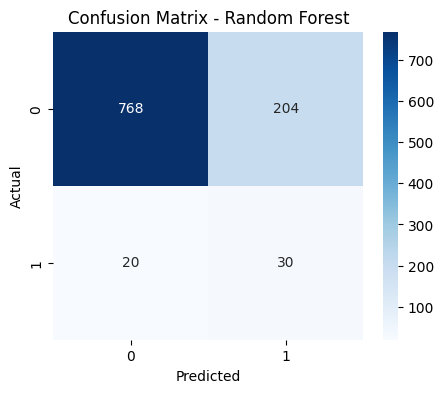

In [ ]:
evaluate_model(
    y_test,
    y_pred_rf,
    "Random Forest"
)


## Evaluasi XGBOOST



===== XGBoost =====
Accuracy : 0.7788649706457925
Precision: 0.12393162393162394
Recall   : 0.58
F1-Score : 0.20422535211267606

Classification Report
              precision    recall  f1-score   support

           0       0.97      0.79      0.87       972
           1       0.12      0.58      0.20        50

    accuracy                           0.78      1022
   macro avg       0.55      0.68      0.54      1022
weighted avg       0.93      0.78      0.84      1022



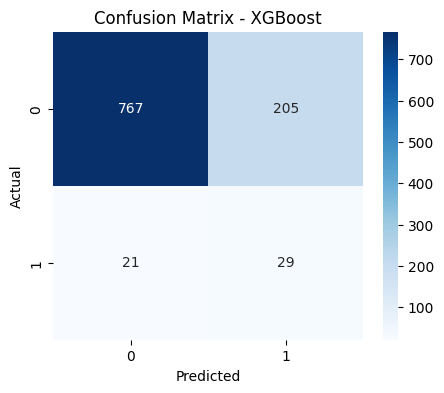

In [ ]:
evaluate_model(
    y_test,
    y_pred_xgb,
    "XGBoost"
)

## Evaluasi SVM



===== SVM =====
Accuracy : 0.7279843444227005
Precision: 0.12987012987012986
Recall   : 0.8
F1-Score : 0.22346368715083798

Classification Report
              precision    recall  f1-score   support

           0       0.99      0.72      0.84       972
           1       0.13      0.80      0.22        50

    accuracy                           0.73      1022
   macro avg       0.56      0.76      0.53      1022
weighted avg       0.94      0.73      0.81      1022



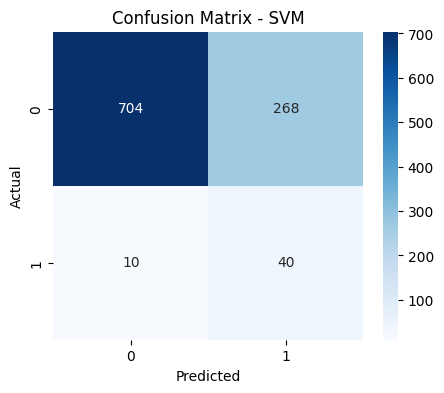

In [ ]:
evaluate_model(
    y_test,
    y_pred_svm,
    "SVM"
)

# Comparison Table

### Random Forest


In [ ]:
import pandas as pd
rf_accuracy  = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall    = recall_score(y_test, y_pred_rf)
rf_f1        = f1_score(y_test, y_pred_rf)

### XGBoost


In [ ]:
xgb_accuracy  = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb)
xgb_recall    = recall_score(y_test, y_pred_xgb)
xgb_f1        = f1_score(y_test, y_pred_xgb)

### SVM


In [ ]:
svm_accuracy  = accuracy_score(y_test, y_pred_svm)
svm_precision = precision_score(y_test, y_pred_svm)
svm_recall    = recall_score(y_test, y_pred_svm)
svm_f1        = f1_score(y_test, y_pred_svm)

In [ ]:
comparison_table = pd.DataFrame({

    'Model': [
        'Random Forest',
        'XGBoost',
        'SVM',
    ],

    'Accuracy': [
        rf_accuracy,
        xgb_accuracy,
        svm_accuracy,
    ],

    'Precision': [
        rf_precision,
        xgb_precision,
        svm_precision,
    ],

    'Recall': [
        rf_recall,
        xgb_recall,
        svm_recall,
    ],

    'F1-Score': [
        rf_f1,
        xgb_f1,
        svm_f1,
    ]

})

print("\nComparison Table")

display(comparison_table)


Comparison Table


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.780822,0.128205,0.60,0.211268
1,XGBoost,0.778865,0.123932,0.58,0.204225
2,SVM,0.727984,0.129870,0.80,0.223464


## Model Terbaik

In [ ]:
best_model = comparison_table.loc[
    comparison_table['F1-Score'].idxmax()
]

print("\nModel Terbaik Berdasarkan F1-Score")
print(best_model)


Model Terbaik Berdasarkan F1-Score
Model             SVM
Accuracy     0.727984
Precision     0.12987
Recall            0.8
F1-Score     0.223464
Name: 2, dtype: object


# **2. SMOTE**

# Balancing Dataset

### Cek Distribusi Target Sebelum Smote

In [ ]:
print("\nJumlah Kelas Training Sebelum SMOTE")
print(y_train.value_counts())


Jumlah Kelas Training Sebelum SMOTE
stroke
0    3889
1     199
Name: count, dtype: int64


### Smote

In [ ]:
from imblearn.over_sampling import SMOTE

# Apply the preprocessor to X_train before SMOTE
# The preprocessor handles both numerical scaling and one-hot encoding
X_train_processed = preprocessor.fit_transform(X_train)

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed, # Use the processed X_train
    y_train
)

### Hasil Setelah Smote

In [ ]:
print("\nJumlah Kelas Training Setelah SMOTE")
print(pd.Series(y_train_smote).value_counts())


Jumlah Kelas Training Setelah SMOTE
stroke
0    3889
1    3889
Name: count, dtype: int64


### Visualisasi Setelah Smote

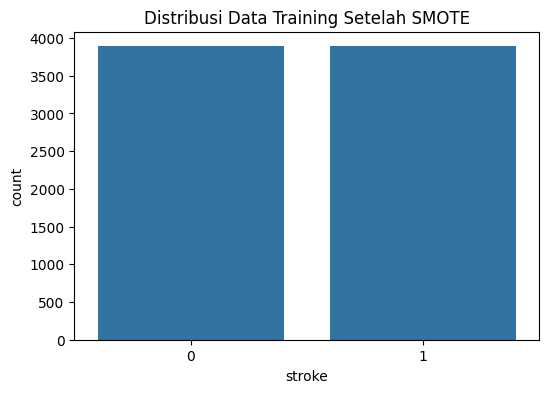

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(x=y_train_smote)

plt.title('Distribusi Data Training Setelah SMOTE')

plt.show()

# Optimasi Hyperparameter

In [ ]:
!pip install scikit-optimize

from sklearn.model_selection import StratifiedKFold
from skopt import BayesSearchCV
from skopt.space import Integer, Real, Categorical
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import ADASYN
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC

##### Stratified K-Fold

In [ ]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
def build_pipeline(model):
    return ImbPipeline(steps=[
        ("preprocess", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("model", model)
    ])

### Random Forest

##### Parameter Random Forest

In [ ]:
rf_params = {
    'model__n_estimators': Integer(50, 300),
    'model__max_depth': Integer(3, 20),
    'model__min_samples_split': Integer(2, 10),
    'model__min_samples_leaf': Integer(1, 10)
}

##### Model Random Forest

In [ ]:
rf_model = RandomForestClassifier(
    random_state=42,
    class_weight='balanced'
)

##### Bayesian Optimization

In [ ]:
rf_opt = BayesSearchCV(
    estimator=build_pipeline(rf_model),

    search_spaces=rf_params,

    n_iter=20,

    cv=skf,

    scoring='f1',

    n_jobs=-1,

    random_state=42
)

rf_opt.fit(X_train, y_train)

print("\nBest Parameter Random Forest")
print(rf_opt.best_params_)


Best Parameter Random Forest
OrderedDict({'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__min_samples_split': 10, 'model__n_estimators': 300})


### XGBOOST

##### Parameter XGBOOST

In [ ]:
xgb_params = {
    'model__n_estimators': Integer(50, 300),
    'model__max_depth': Integer(3, 15),
    'model__learning_rate': Real(0.01, 0.3, prior='log-uniform'),
    'model__subsample': Real(0.5, 1.0, prior='uniform'),
    'model__colsample_bytree': Real(0.5, 1.0, prior='uniform')
}

##### Model XGBOOST

In [ ]:
scale_pos_weight = (
    y_train.value_counts()[0] /
    y_train.value_counts()[1]
)

In [ ]:
xgb_model = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    scale_pos_weight=scale_pos_weight
)

##### Bayesian Optimization

In [ ]:
xgb_opt = BayesSearchCV(
    estimator=build_pipeline(xgb_model),

    search_spaces=xgb_params,

    n_iter=20,

    cv=skf,

    scoring='f1',

    n_jobs=-1,

    random_state=42
)

xgb_opt.fit(X_train, y_train)

print("\nBest Parameter XGBoost")
print(xgb_opt.best_params_)


Best Parameter XGBoost
OrderedDict({'model__colsample_bytree': 0.7298362654212309, 'model__learning_rate': 0.01472455746711106, 'model__max_depth': 10, 'model__n_estimators': 232, 'model__subsample': 0.538723419207647})


### Support Vector Machine (SVM)

##### Parameter SVM

In [ ]:
svm_params = {
    'model__C': Real(0.1, 100.0, prior='log-uniform'),
    'model__gamma': Real(0.0001, 1.0, prior='log-uniform'),
    'model__kernel': Categorical(['rbf'])
}

##### Model SVM

In [ ]:
svm_model = SVC(
    probability=True,
    random_state=42,
    class_weight='balanced'
)

##### Bayesian Optimization

In [ ]:
svm_opt = BayesSearchCV(
    estimator=build_pipeline(svm_model),

    search_spaces=svm_params,

    n_iter=20,

    cv=skf,

    scoring='f1',

    n_jobs=-1,

    random_state=42
)

svm_opt.fit(X_train, y_train)

print("\nBest Parameter SVM")
print(svm_opt.best_params_)


Best Parameter SVM
OrderedDict({'model__C': 0.1, 'model__gamma': 0.0001, 'model__kernel': 'rbf'})


# Pelatihan Model

### Random Forest

In [ ]:
best_rf = rf_opt.best_estimator_

### XGBOOST

In [ ]:
best_xgb = xgb_opt.best_estimator_

### SVM

In [ ]:
best_svm = svm_opt.best_estimator_

# Prediksi Model

###Random Forest

In [ ]:
y_pred_rf = best_rf.predict(X_test)

###XGBoost

In [ ]:
y_pred_xgb = best_xgb.predict(X_test)

###SVM


In [ ]:
y_pred_svm = best_svm.predict(X_test)

# Evaluasi Model

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
def evaluate_model(y_test, y_pred, model_name):

    print(f"\n===== {model_name} =====")

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1-Score :", f1)

    print("\nClassification Report")
    print(classification_report(y_test, y_pred))

    # Confusion

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5,4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues'
    )

    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')

    plt.show()



##Evaluasi Random Forest



===== Random Forest =====
Accuracy : 0.7250489236790607
Precision: 0.12131147540983607
Recall   : 0.74
F1-Score : 0.2084507042253521

Classification Report
              precision    recall  f1-score   support

           0       0.98      0.72      0.83       972
           1       0.12      0.74      0.21        50

    accuracy                           0.73      1022
   macro avg       0.55      0.73      0.52      1022
weighted avg       0.94      0.73      0.80      1022



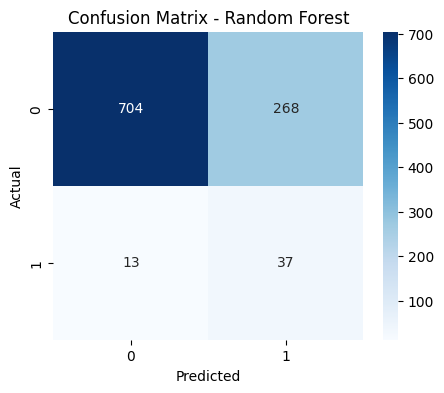

In [ ]:
evaluate_model(
    y_test,
    y_pred_rf,
    "Random Forest"
)


## Evaluasi XGBOOST



===== XGBoost =====
Accuracy : 0.7475538160469667
Precision: 0.10305343511450382
Recall   : 0.54
F1-Score : 0.17307692307692307

Classification Report
              precision    recall  f1-score   support

           0       0.97      0.76      0.85       972
           1       0.10      0.54      0.17        50

    accuracy                           0.75      1022
   macro avg       0.54      0.65      0.51      1022
weighted avg       0.93      0.75      0.82      1022



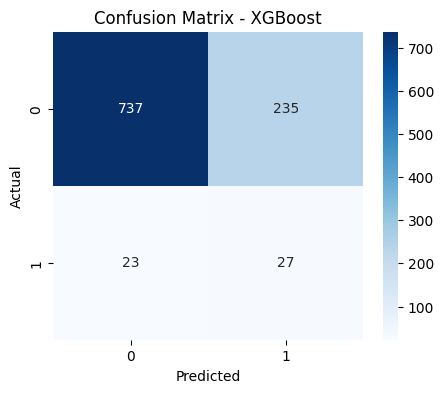

In [ ]:
evaluate_model(
    y_test,
    y_pred_xgb,
    "XGBoost"
)

## Evaluasi SVM



===== SVM =====
Accuracy : 0.8395303326810176
Precision: 0.1724137931034483
Recall   : 0.6
F1-Score : 0.26785714285714285

Classification Report
              precision    recall  f1-score   support

           0       0.98      0.85      0.91       972
           1       0.17      0.60      0.27        50

    accuracy                           0.84      1022
   macro avg       0.57      0.73      0.59      1022
weighted avg       0.94      0.84      0.88      1022



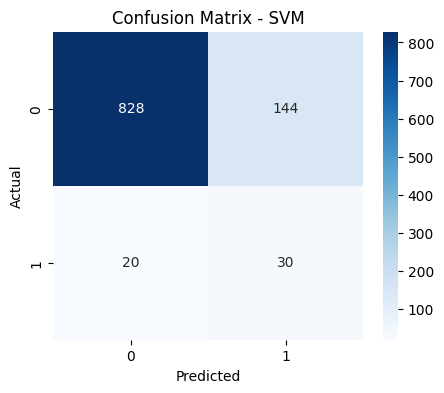

In [ ]:
evaluate_model(
    y_test,
    y_pred_svm,
    "SVM"
)

# Comparison Table

### Random Forest


In [ ]:
import pandas as pd
rf_accuracy  = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall    = recall_score(y_test, y_pred_rf)
rf_f1        = f1_score(y_test, y_pred_rf)

### XGBoost


In [ ]:
xgb_accuracy  = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb)
xgb_recall    = recall_score(y_test, y_pred_xgb)
xgb_f1        = f1_score(y_test, y_pred_xgb)

### SVM


In [ ]:
svm_accuracy  = accuracy_score(y_test, y_pred_svm)
svm_precision = precision_score(y_test, y_pred_svm)
svm_recall    = recall_score(y_test, y_pred_svm)
svm_f1        = f1_score(y_test, y_pred_svm)

In [ ]:
comparison_table = pd.DataFrame({

    'Model': [
        'Random Forest',
        'XGBoost',
        'SVM',
    ],

    'Accuracy': [
        rf_accuracy,
        xgb_accuracy,
        svm_accuracy,
    ],

    'Precision': [
        rf_precision,
        xgb_precision,
        svm_precision,
    ],

    'Recall': [
        rf_recall,
        xgb_recall,
        svm_recall,
    ],

    'F1-Score': [
        rf_f1,
        xgb_f1,
        svm_f1,
    ]

})

print("\nComparison Table")

display(comparison_table)


Comparison Table


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.725049,0.121311,0.74,0.208451
1,XGBoost,0.747554,0.103053,0.54,0.173077
2,SVM,0.839530,0.172414,0.60,0.267857


## Model Terbaik

In [ ]:
best_model = comparison_table.loc[
    comparison_table['F1-Score'].idxmax()
]

print("\nModel Terbaik Berdasarkan F1-Score")
print(best_model)


Model Terbaik Berdasarkan F1-Score
Model             SVM
Accuracy      0.83953
Precision    0.172414
Recall            0.6
F1-Score     0.267857
Name: 2, dtype: object


# Comparison Table Semua Teknik

In [ ]:
import pandas as pd

# Filter comparison_table_full to get SMOTE results
smote_results = comparison_table_full[comparison_table_full['Technique'] == 'SMOTE'].copy()

# Filter comparison_table_full to get ADASYN results
adasyn_results = comparison_table_full[comparison_table_full['Technique'] == 'ADASYN'].copy()

print("\nHasil SMOTE")
display(smote_results.sort_values(by="F1-Score", ascending=False))

print("\nHasil ADASYN")
display(adasyn_results.sort_values(by="F1-Score", ascending=False))

smote_best = smote_results.sort_values(by="F1-Score", ascending=False).iloc[0]
adasyn_best = adasyn_results.sort_values(by="F1-Score", ascending=False).iloc[0]

comparison_table = pd.DataFrame([
    {
        "Technique": "SMOTE",
        "Best Model": smote_best["Model"],
        "Accuracy": smote_best["Accuracy"],
        "Precision": smote_best["Precision"],
        "Recall": smote_best["Recall"],
        "F1-Score": smote_best["F1-Score"]
    },
    {
        "Technique": "ADASYN",
        "Best Model": adasyn_best["Model"],
        "Accuracy": adasyn_best["Accuracy"],
        "Precision": adasyn_best["Precision"],
        "Recall": adasyn_best["Recall"],
        "F1-Score": adasyn_best["F1-Score"]
    }
])

print("\nComparison Table")
display(comparison_table)


Hasil SMOTE


,Model,Accuracy,Precision,Recall,F1-Score,Technique
2,SVM,0.839530,0.172414,0.60,0.267857,SMOTE
0,Random Forest,0.725049,0.121311,0.74,0.208451,SMOTE
1,XGBoost,0.747554,0.103053,0.54,0.173077,SMOTE



Hasil ADASYN


,Model,Accuracy,Precision,Recall,F1-Score,Technique
5,SVM,0.727984,0.129870,0.80,0.223464,ADASYN
3,Random Forest,0.780822,0.128205,0.60,0.211268,ADASYN
4,XGBoost,0.778865,0.123932,0.58,0.204225,ADASYN



Comparison Table


,Technique,Best Model,Accuracy,Precision,Recall,F1-Score
0,SMOTE,SVM,0.839530,0.172414,0.6,0.267857
1,ADASYN,SVM,0.727984,0.129870,0.8,0.223464


# Model Terbaik dari Semua Teknik

In [ ]:
best_model = comparison_table.loc[
    comparison_table['F1-Score'].idxmax()
]

print("\nModel Terbaik Berdasarkan F1-Score")
print(best_model)


Model Terbaik Berdasarkan F1-Score
Technique        SMOTE
Best Model         SVM
Accuracy       0.83953
Precision     0.172414
Recall             0.6
F1-Score      0.267857
Name: 0, dtype: object


# Visualisasi Perbandingan Model

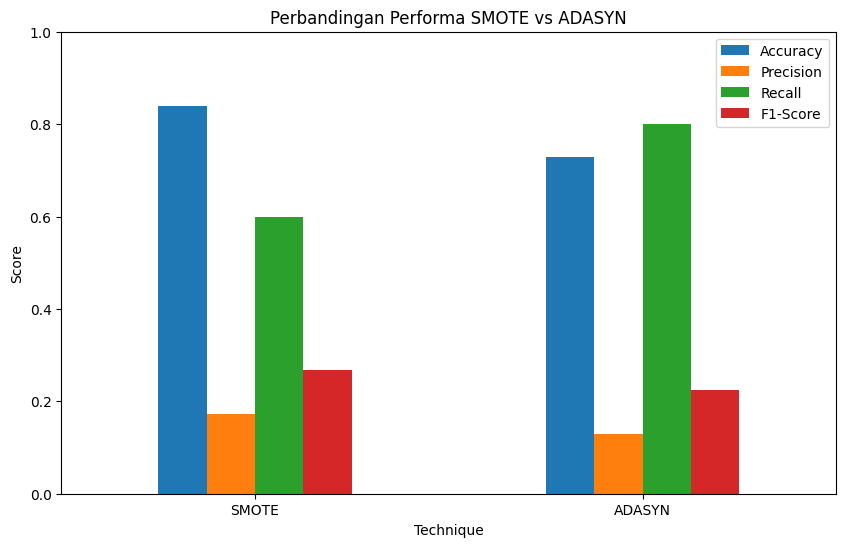

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Re-construct comparison_table to ensure it has the 'Technique' column
# using smote_best and adasyn_best from the kernel state.
comparison_table = pd.DataFrame([
    {
        "Technique": "SMOTE",
        "Best Model": smote_best["Model"],
        "Accuracy": smote_best["Accuracy"],
        "Precision": smote_best["Precision"],
        "Recall": smote_best["Recall"],
        "F1-Score": smote_best["F1-Score"]
    },
    {
        "Technique": "ADASYN",
        "Best Model": adasyn_best["Model"],
        "Accuracy": adasyn_best["Accuracy"],
        "Precision": adasyn_best["Precision"],
        "Recall": adasyn_best["Recall"],
        "F1-Score": adasyn_best["F1-Score"]
    }
])

comparison_table.set_index('Technique')[[
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score'
]].plot(
    kind='bar',
    figsize=(10,6)
)

plt.title('Perbandingan Performa SMOTE vs ADASYN')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.show()

# Visualisasi Perbandingan Model

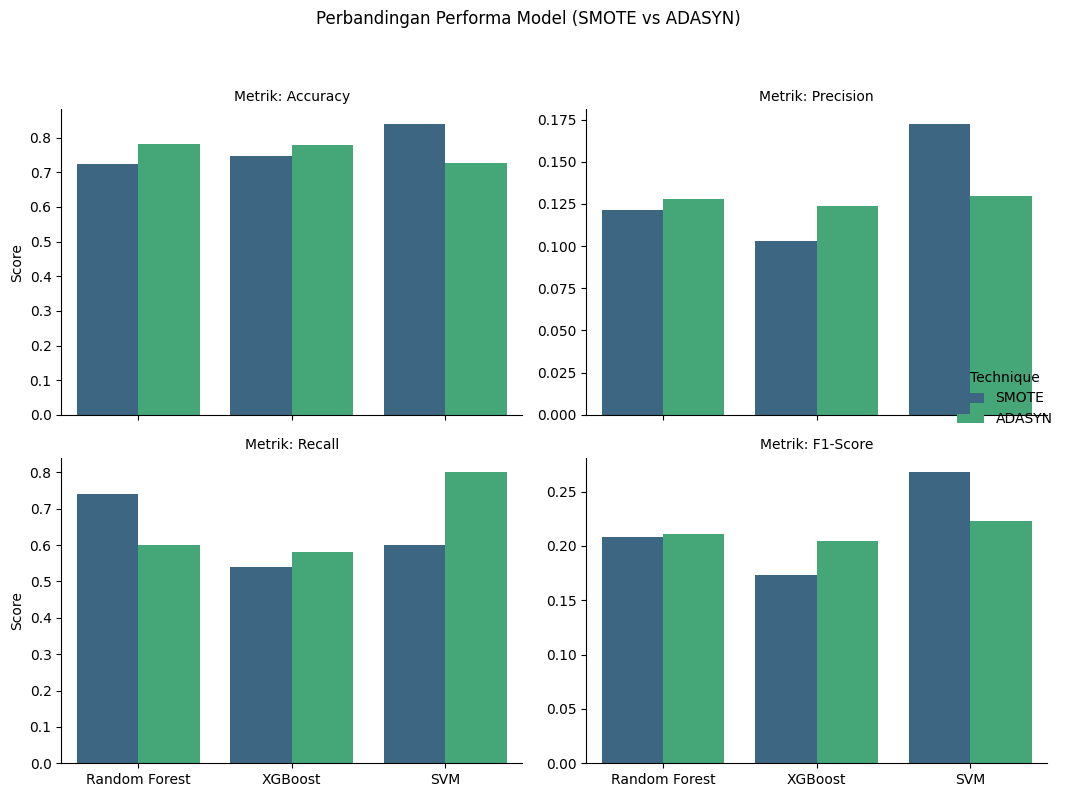

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Combine smote_results and adasyn_results for a full comparison of all models
smote_results['Technique'] = 'SMOTE'
adasyn_results['Technique'] = 'ADASYN'

comparison_table_full = pd.concat(
    [smote_results, adasyn_results],
    ignore_index=True
)

# Melt the DataFrame to prepare for seaborn barplot
comparison_melted = pd.melt(
    comparison_table_full,
    id_vars=['Model', 'Technique'],
    var_name='Metric',
    value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score']
)

# Use sns.catplot instead of sns.barplot for facet grids
g = sns.catplot(
    x='Model',
    y='value',
    hue='Technique',
    col='Metric',
    data=comparison_melted,
    col_wrap=2, # Wrap columns after 2 plots
    kind='bar', # Specify bar plot
    palette='viridis',
    height=4, # Height of each facet
    aspect=1.2, # Aspect ratio of each facet
    sharey=False # Allow each facet to have its own y-axis scale
)

# Set common title for the FacetGrid
g.set_axis_labels("", "Score") # Remove x-axis label, set y-axis label
g.set_titles("Metrik: {col_name}") # Set title for each facet
g.fig.suptitle('Perbandingan Performa Model (SMOTE vs ADASYN)', y=1.02) # Set overall super title

# Adjust layout to prevent titles from overlapping
plt.tight_layout(rect=[0, 0.03, 1, 0.98])
plt.show()